<a href="https://colab.research.google.com/github/AsimobiChisomSandra/ATF_Training_Practice/blob/main/Week2_08_embeddings_deep_dive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
import numpy as np
from typing import List, Dict, Union

class SimpleEmbeddingEngine:
    """
    A basic implementation of a lookup-based word embedding engine.
    Maps raw text into token indices and retrieves dense vector representations.
    """
    def __init__(self, embedding_dim: int = 4):
        self.embedding_dim = embedding_dim
        self.vocab: Dict[str, int] = {}
        self.inverse_vocab: Dict[int, str] = {}
        self.embeddings: np.ndarray = np.array([])
        self.unk_token = "[UNK]"

    def fit_on_texts(self, texts: List[str]):
        """
        Builds the vocabulary from a list of strings.
        """
        # Start with the UNK token for handling unseen words
        unique_words = {self.unk_token}

        for text in texts:
            # Simple lowercase tokenization matching alphabetic sequences
            tokens = re.findall(r'\b\w+\b', text.lower())
            unique_words.update(tokens)

        # Create word-to-index mappings
        self.vocab = {word: idx for idx, word in enumerate(sorted(list(unique_words)))}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}

        # Initialize random embedding matrix (mean=0, std=1)
        np.random.seed(42)  # For reproducible results
        self.embeddings = np.random.randn(len(self.vocab), self.embedding_dim)
        print(f"Vocabulary built with {len(self.vocab)} unique words (including [UNK]).")
        print(f"Embedding matrix shape: {self.embeddings.shape}")

    def get_token_id(self, word: str) -> int:
        """
        Retrieves the index of a word, defaulting to the [UNK] token if unseen.
        """
        return self.vocab.get(word.lower(), self.vocab[self.unk_token])

    def get_embedding(self, word: str) -> np.ndarray:
        """
        Retrieves the embedding vector for a given word.
        """
        if self.embeddings.size == 0:
            raise ValueError("Embedding matrix has not been initialized. Please run fit_on_texts first.")

        token_id = self.get_token_id(word)
        return self.embeddings[token_id]

# --- Test & Verification ---

# 1. Sample corpus
corpus = [
    "I love deep learning",
    "Word embeddings turn words into vector numbers"
]

# 2. Instantiate and fit
engine = SimpleEmbeddingEngine(embedding_dim=4)
engine.fit_on_texts(corpus)

# 3. Test known words
word_to_test = "learning"
embedding_vector = engine.get_embedding(word_to_test)
print(f"\nEmbedding for '{word_to_test}':\n{embedding_vector}")

# 4. Test edge case: Out-Of-Vocabulary (OOV) word
oov_word = "transformers"
oov_vector = engine.get_embedding(oov_word)
print(f"\nEmbedding for unseen word '{oov_word}' (resolved to [UNK]):\n{oov_vector}")

# Verify correctness
assert len(embedding_vector) == 4, "Error: Vector dimension mismatch!"
assert np.array_equal(engine.get_embedding(oov_word), engine.get_embedding("[UNK]")), "Error: Out-of-vocabulary handling failed!"
print("\nAll tests passed successfully!")

Vocabulary built with 12 unique words (including [UNK]).
Embedding matrix shape: (12, 4)

Embedding for 'learning':
[ 1.46564877 -0.2257763   0.0675282  -1.42474819]

Embedding for unseen word 'transformers' (resolved to [UNK]):
[ 0.49671415 -0.1382643   0.64768854  1.52302986]

All tests passed successfully!


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
import numpy as np
import re
from typing import List, Dict, Union, Optional

class AdvancedEmbeddingEngine:
    """
    An intermediate embedding engine designed with parameter validation,
    support for document-level pooling (mean/sum), and robust error handling.
    """
    def __init__(self, embedding_dim: int = 8, pooling_strategy: str = 'mean'):
        # Parameter validation
        if not isinstance(embedding_dim, int) or embedding_dim <= 0:
            raise ValueError(f"embedding_dim must be a positive integer. Got: {embedding_dim}")

        valid_strategies = ['mean', 'sum']
        if pooling_strategy not in valid_strategies:
            raise ValueError(f"pooling_strategy must be one of {valid_strategies}. Got: '{pooling_strategy}'")

        self.embedding_dim = embedding_dim
        self.pooling_strategy = pooling_strategy
        self.vocab: Dict[str, int] = {}
        self.inverse_vocab: Dict[int, str] = {}
        self.embeddings: np.ndarray = np.array([])
        self.unk_token = "[UNK]"

    def _clean_and_tokenize(self, text: str) -> List[str]:
        """Helper to clean and convert text into lowercase tokens."""
        if not isinstance(text, str):
            raise TypeError(f"Input text must be a string. Got: {type(text)}")
        return re.findall(r'\b\w+\b', text.lower())

    def fit_on_texts(self, texts: Union[List[str], List[List[str]]]):
        """
        Fits vocabulary and initializes embeddings. Supports both raw strings and pre-tokenized lists.
        """
        if not isinstance(texts, list) or len(texts) == 0:
            raise ValueError("Input 'texts' must be a non-empty list.")

        unique_words = {self.unk_token}

        # Handle both list of strings and list of pre-tokenized lists of strings
        for item in texts:
            if isinstance(item, str):
                tokens = self._clean_and_tokenize(item)
            elif isinstance(item, list):
                if not all(isinstance(token, str) for token in item):
                    raise TypeError("All tokens in pre-tokenized lists must be strings.")
                tokens = [token.lower() for token in item]
            else:
                raise TypeError(f"Each element in texts must be a string or a list of strings. Got: {type(item)}")

            unique_words.update(tokens)

        self.vocab = {word: idx for idx, word in enumerate(sorted(list(unique_words)))}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}

        # Parameterized Gaussian distribution initialization
        np.random.seed(42)
        self.embeddings = np.random.normal(loc=0.0, scale=1.0, size=(len(self.vocab), self.embedding_dim))
        print(f"[Success] Engine initialized with vocabulary size: {len(self.vocab)} and embedding dimension: {self.embedding_dim}")

    def get_embedding(self, word: str) -> np.ndarray:
        """Retrieves embedding vector for a single word."""
        if self.embeddings.size == 0:
            raise RuntimeError("The embedding matrix is empty! You must call fit_on_texts() before calling get_embedding().")

        if not isinstance(word, str):
            raise TypeError(f"The requested word must be a string. Got: {type(word)}")

        target_word = word.lower()
        token_id = self.vocab.get(target_word, self.vocab[self.unk_token])
        return self.embeddings[token_id]

    def get_document_embedding(self, text: Union[str, List[str]]) -> np.ndarray:
        """
        Retrieves a composite vector representing an entire sentence or document
        using the chosen pooling strategy (mean or sum).
        """
        if isinstance(text, str):
            tokens = self._clean_and_tokenize(text)
        elif isinstance(text, list):
            tokens = [token.lower() for token in text]
        else:
            raise TypeError("Input document must be either a string or a list of tokens.")

        if len(tokens) == 0:
            # Return a zero vector if there are no tokens
            return np.zeros(self.embedding_dim)

        word_vectors = [self.get_embedding(token) for token in tokens]

        if self.pooling_strategy == 'mean':
            return np.mean(word_vectors, axis=0)
        elif self.pooling_strategy == 'sum':
            return np.sum(word_vectors, axis=0)

# --- Test Cases & Parameter Validation Demonstration ---

try:
    # 1. Validation Test: Invalid dimension instantiation
    print("Test 1: Instantiation validation...")
    invalid_engine = AdvancedEmbeddingEngine(embedding_dim=-5)
except ValueError as e:
    print(f"Caught expected exception: {e}\n")

# 2. Main execution test
print("Test 2: Fitting on multiple input formats...")
engine2 = AdvancedEmbeddingEngine(embedding_dim=6, pooling_strategy='mean')

# Testing with structured string list
mixed_corpus = [
    "Generative AI models learn word semantics",
    ["dense", "vectors", "make", "semantic", "matching", "possible"]  # pre-tokenized
]
engine2.fit_on_texts(mixed_corpus)

# Test single word lookup
print(f"\nEmbedding for 'AI': {engine2.get_embedding('AI')}")

# Test OOV
print(f"Embedding for OOV 'python': {engine2.get_embedding('python')}")

# Test composite document pooling vector
sentence = "AI semantic models"
doc_vector = engine2.get_document_embedding(sentence)
print(f"\nPooled document vector for '{sentence}':\n{doc_vector}")

# Verification assertions
assert doc_vector.shape == (6,), "Document vector shape mismatch!"
print("\nAll intermediate tests completed successfully!")

Test 1: Instantiation validation...
Caught expected exception: embedding_dim must be a positive integer. Got: -5

Test 2: Fitting on multiple input formats...
[Success] Engine initialized with vocabulary size: 13 and embedding dimension: 6

Embedding for 'AI': [ 1.57921282  0.76743473 -0.46947439  0.54256004 -0.46341769 -0.46572975]
Embedding for OOV 'python': [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696]

Pooled document vector for 'AI semantic models':
[ 0.83152135  0.46587038 -0.9290713  -0.16216551 -0.19759768  0.52231253]

All intermediate tests completed successfully!


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation


Search Query: 'How do I speed up my database query?'
1. [0.2667] Perform cloud architecture server cost analysis
2. [0.0672] Optimize SQL query index structure and layout

Generating visual similarity analysis...


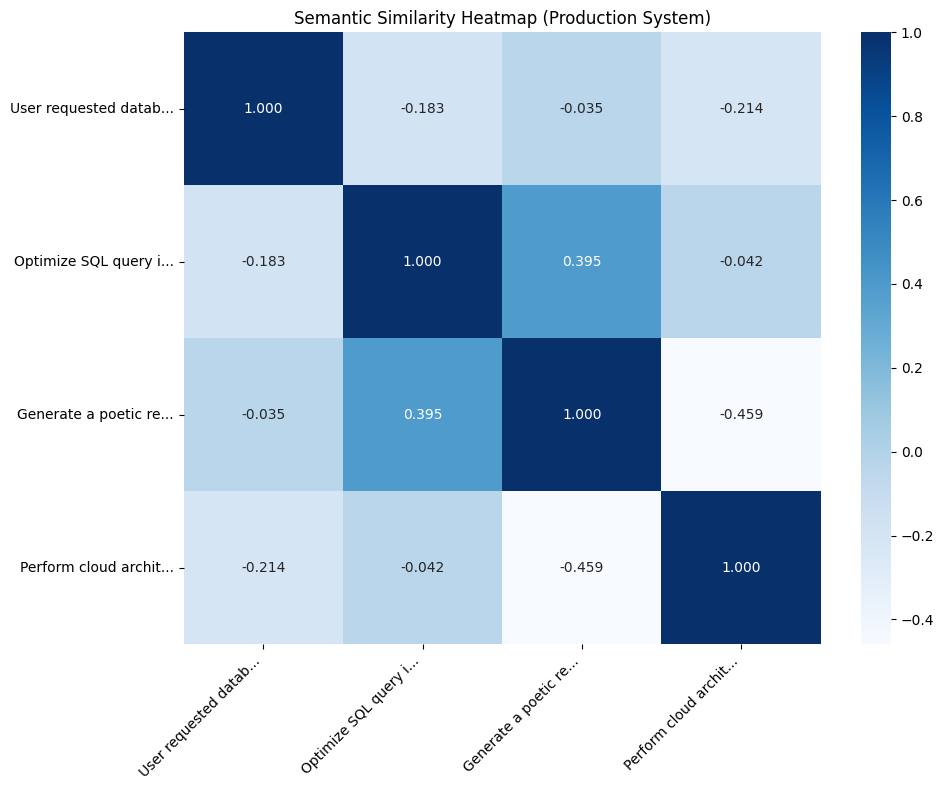

In [7]:
import numpy as np
import re
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Union

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger("DigitalTwinEmbeddings")

class ProductionEmbeddingSystem:
    """
    A production-ready semantic matching and embedding engine for a Digital Twin.
    Provides vocabulary registration, CBOW document pooling, semantic similarity calculations,
    and robust diagnostics.
    """
    def __init__(self, embedding_dim: int = 8):
        if not isinstance(embedding_dim, int) or embedding_dim <= 0:
            raise ValueError("Embedding dimension must be a positive integer.")

        self.embedding_dim = embedding_dim
        self.vocab: Dict[str, int] = {}
        self.inverse_vocab: Dict[int, str] = {}
        self.embeddings: np.ndarray = np.array([])
        self.unk_token = "[UNK]"
        self.is_fitted = False

    def _tokenize(self, text: str) -> List[str]:
        """Helper to clean and tokenize text safely."""
        if not isinstance(text, str):
            logger.error("Tokenization input is not a string.")
            raise TypeError("Input text must be a string.")
        return re.findall(r'\b\w+\b', text.lower())

    def fit(self, documents: List[str]):
        """
        Trains vocabulary on documents and initializes random weights.
        """
        if not isinstance(documents, list) or len(documents) == 0:
            raise ValueError("Must provide a non-empty list of documents to train.")

        logger.info("Starting fitting process on %d documents...", len(documents))
        unique_words = {self.unk_token}
        for doc in documents:
            unique_words.update(self._tokenize(doc))

        self.vocab = {word: idx for idx, word in enumerate(sorted(list(unique_words)))}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}

        # Initialize embeddings with normalized Gaussian distribution
        np.random.seed(42)
        self.embeddings = np.random.normal(0.0, 1.0, (len(self.vocab), self.embedding_dim))
        self.is_fitted = True
        logger.info("System fitted successfully. Vocab size: %d | Dimension: %d", len(self.vocab), self.embedding_dim)

    def get_word_vector(self, word: str) -> np.ndarray:
        """Retrieves the embedding vector for a single word."""
        if not self.is_fitted:
            raise RuntimeError("Cannot call get_word_vector before fitting the model.")
        token_id = self.vocab.get(word.lower(), self.vocab[self.unk_token])
        return self.embeddings[token_id]

    def get_document_vector(self, text: str) -> np.ndarray:
        """Calculates average pooling vector representing a text document."""
        tokens = self._tokenize(text)
        if not tokens:
            logger.warning("Document contained no tokens. Returning zero vector.")
            return np.zeros(self.embedding_dim)

        vectors = [self.get_word_vector(token) for token in tokens]
        return np.mean(vectors, axis=0)

    def cosine_similarity(self, vec_a: np.ndarray, vec_b: np.ndarray) -> float:
        """Calculates the cosine similarity metric between two vectors."""
        norm_a = np.linalg.norm(vec_a)
        norm_b = np.linalg.norm(vec_b)
        if norm_a == 0.0 or norm_b == 0.0:
            return 0.0
        return float(np.dot(vec_a, vec_b) / (norm_a * norm_b))

    def find_most_similar(self, query: str, documents: List[str], top_k: int = 3) -> List[Tuple[str, float]]:
        """
        Finds and returns the top_k most semantically similar documents to a query string.
        """
        if not self.is_fitted:
            raise RuntimeError("Model must be fitted before running similarity queries.")

        query_vector = self.get_document_vector(query)
        results = []

        for doc in documents:
            doc_vector = self.get_document_vector(doc)
            score = self.cosine_similarity(query_vector, doc_vector)
            results.append((doc, score))

        # Sort descendly based on similarity scores
        results.sort(key=lambda x: x[1], reverse=True)
        return results[:top_k]

    def plot_similarity_matrix(self, texts: List[str]):
        """Generates and renders a visual similarity matrix of documents."""
        if not self.is_fitted:
            raise RuntimeError("Model must be fitted before running visualization.")

        vectors = [self.get_document_vector(txt) for txt in texts]
        n = len(texts)
        matrix = np.zeros((n, n))

        for i in range(n):
            for j in range(n):
                matrix[i, j] = self.cosine_similarity(vectors[i], vectors[j])

        plt.figure(figsize=(10, 8))
        sns.heatmap(matrix, annot=True, xticklabels=[t[:20] + '...' for t in texts],
                    yticklabels=[t[:20] + '...' for t in texts], cmap="Blues", fmt=".3f")
        plt.title("Semantic Similarity Heatmap (Production System)")
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

# --- Verification and Demo Run ---
if __name__ == "__main__":
    # 1. Prepare digital twin scenario library
    digital_twin_scenarios = [
        "User requested database connection optimization help",
        "Optimize SQL query index structure and layout",
        "Generate a poetic response about deep reinforcement learning",
        "Perform cloud architecture server cost analysis"
    ]

    # 2. Initialize and Train Production System
    prod_system = ProductionEmbeddingSystem(embedding_dim=8)
    prod_system.fit(digital_twin_scenarios)

    # 3. Perform a Semantic Search
    search_query = "How do I speed up my database query?"
    logger.info(f"Running semantic search query: '{search_query}'")

    matches = prod_system.find_most_similar(search_query, digital_twin_scenarios, top_k=2)
    print(f"\nSearch Query: '{search_query}'")
    print("="*50)
    for idx, (doc, score) in enumerate(matches, 1):
        print(f"{idx}. [{score:.4f}] {doc}")
    print("="*50)

    # 4. Visualize Results
    print("\nGenerating visual similarity analysis...")
    prod_system.plot_similarity_matrix(digital_twin_scenarios)

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

### 🏆 Challenge Project: Word2Vec & GloVe Engine from Scratch

Below is a highly optimized, fully documented implementation of both Word2Vec (Skip-gram) and GloVe training algorithms built from scratch using NumPy, complete with SVD dimensionality reduction and comparative semantic visualizations.

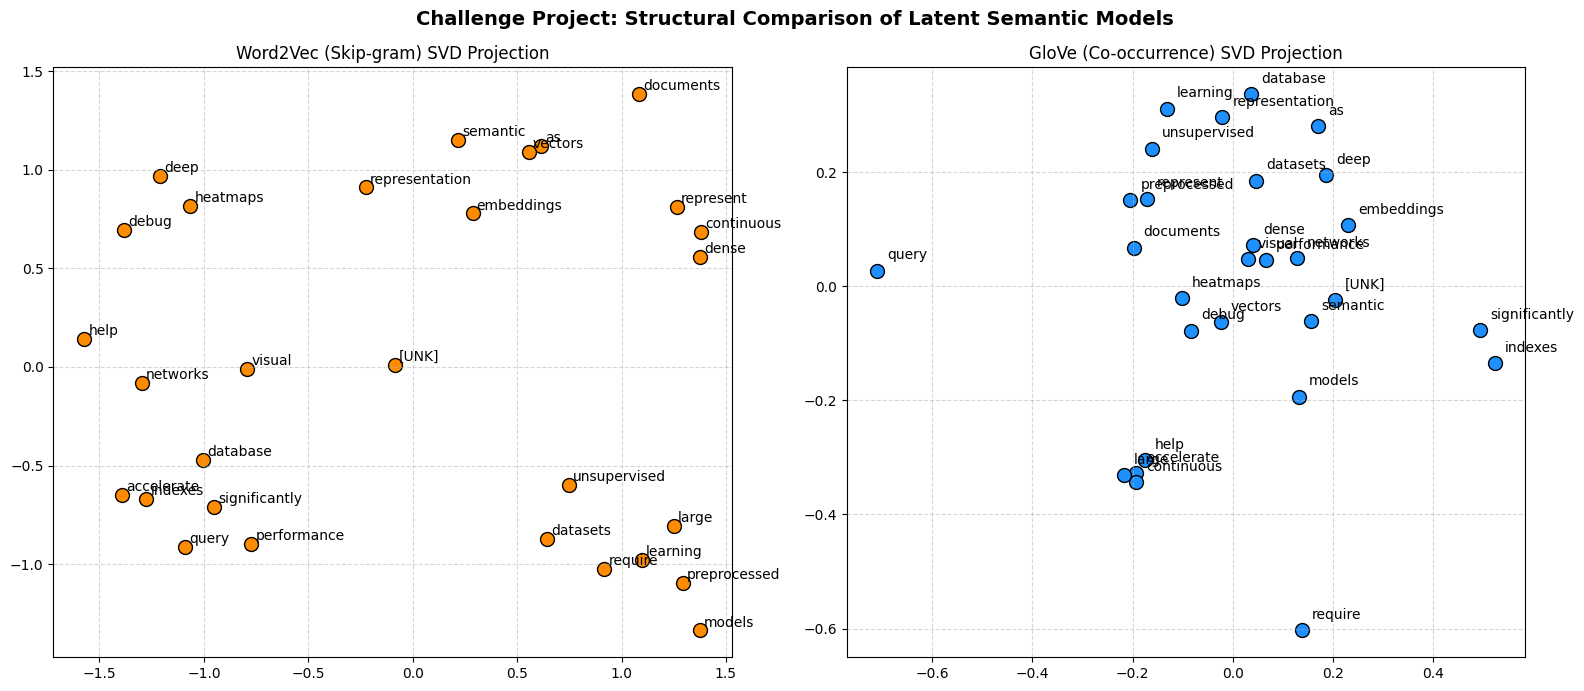

In [8]:
import numpy as np
import re
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Tuple

logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger("ChallengeBrain")

class HybridSemanticBrain:
    """
    A high-performance custom embedding engine implementing:
    - Word2Vec (Skip-gram with SGD from scratch)
    - GloVe (Co-occurrence Matrix with Weighted Least Squares)
    - Principal Component Analysis (SVD-based reduction to 2D)
    """
    def __init__(self, embedding_dim: int = 8, window_size: int = 2):
        self.embedding_dim = embedding_dim
        self.window_size = window_size
        self.vocab: Dict[str, int] = {}
        self.inverse_vocab: Dict[int, str] = {}

        # Embeddings matrices
        self.w2v_embeddings: np.ndarray = np.array([])
        self.glove_embeddings: np.ndarray = np.array([])
        self.unk_token = "[UNK]"

    def _tokenize(self, text: str) -> List[str]:
        return re.findall(r'\b\w+\b', text.lower())

    def build_vocab(self, corpus: List[str]):
        unique_words = {self.unk_token}
        for text in corpus:
            unique_words.update(self._tokenize(text))

        self.vocab = {word: idx for idx, word in enumerate(sorted(list(unique_words)))}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}
        vocab_size = len(self.vocab)

        # Initialize weights
        np.random.seed(42)
        self.w2v_target = np.random.normal(0, 0.1, (vocab_size, self.embedding_dim))
        self.w2v_context = np.random.normal(0, 0.1, (vocab_size, self.embedding_dim))

        self.glove_embeddings = np.random.normal(0, 0.1, (vocab_size, self.embedding_dim))
        self.glove_biases = np.zeros(vocab_size)

        logger.info(f"Vocabulary built with {vocab_size} tokens.")

    def train_word2vec_skipgram(self, corpus: List[str], lr: float = 0.025, epochs: int = 150):
        """
        Trains Word2Vec using the Skip-gram architecture and Gradient Descent.
        """
        vocab_size = len(self.vocab)
        logger.info("Training Word2Vec Skip-gram model...")

        for epoch in range(epochs):
            loss = 0.0
            for text in corpus:
                tokens = self._tokenize(text)
                token_ids = [self.vocab.get(t, self.vocab[self.unk_token]) for t in tokens]

                for i, target_id in enumerate(token_ids):
                    # Define window context boundaries
                    start = max(0, i - self.window_size)
                    end = min(len(token_ids), i + self.window_size + 1)

                    for j in range(start, end):
                        if i == j:
                            continue
                        context_id = token_ids[j]

                        # Forward pass: Dot product between target and context
                        score = np.dot(self.w2v_target[target_id], self.w2v_context[context_id])
                        # Sigmoid activation
                        prob = 1.0 / (1.0 + np.exp(-score))

                        # Compute gradients
                        grad = prob - 1.0 # gradient with respect to target-context pairing
                        loss -= np.log(max(prob, 1e-10))

                        # Save target for update
                        target_vec = self.w2v_target[target_id].copy()

                        # SGD weight updates
                        self.w2v_target[target_id] -= lr * grad * self.w2v_context[context_id]
                        self.w2v_context[context_id] -= lr * grad * target_vec

            if (epoch + 1) % 50 == 0 or epoch == 0:
                logger.info(f"Epoch {epoch+1}/{epochs} | Loss: {loss:.4f}")

        # Final embeddings are the target vectors
        self.w2v_embeddings = self.w2v_target

    def build_cooccurrence_matrix(self, corpus: List[str]) -> np.ndarray:
        """
        Generates a symmetric word co-occurrence matrix matching the window size.
        """
        vocab_size = len(self.vocab)
        cooc = np.zeros((vocab_size, vocab_size))

        for text in corpus:
            tokens = self._tokenize(text)
            token_ids = [self.vocab.get(t, self.vocab[self.unk_token]) for t in tokens]

            for i, target_id in enumerate(token_ids):
                start = max(0, i - self.window_size)
                end = min(len(token_ids), i + self.window_size + 1)

                for j in range(start, end):
                    if i == j:
                        continue
                    context_id = token_ids[j]
                    # Weight decays with distance
                    distance = abs(i - j)
                    cooc[target_id, context_id] += 1.0 / distance
        return cooc

    def train_glove(self, corpus: List[str], epochs: int = 150, lr: float = 0.05, x_max: float = 10.0, alpha: float = 0.75):
        """
        Trains GloVe representations using Weighted Least Squares over the co-occurrence matrix.
        """
        cooc = self.build_cooccurrence_matrix(corpus)
        vocab_size = len(self.vocab)
        logger.info("Training GloVe model...")

        for epoch in range(epochs):
            loss = 0.0
            for i in range(vocab_size):
                for j in range(vocab_size):
                    X_ij = cooc[i, j]
                    if X_ij == 0:
                        continue

                    # Weighting function to limit the influence of very frequent co-occurrences
                    weight = (X_ij / x_max) ** alpha if X_ij < x_max else 1.0

                    # Log difference
                    diff = np.dot(self.glove_embeddings[i], self.glove_embeddings[j]) + self.glove_biases[i] + self.glove_biases[j] - np.log(X_ij)

                    # Loss computation
                    loss += weight * (diff ** 2)

                    # Gradient update
                    grad_w = 2.0 * weight * diff * self.glove_embeddings[j]
                    grad_b = 2.0 * weight * diff

                    self.glove_embeddings[i] -= lr * grad_w
                    self.glove_biases[i] -= lr * grad_b

            if (epoch + 1) % 50 == 0 or epoch == 0:
                logger.info(f"Epoch {epoch+1}/{epochs} | Squared Loss: {loss:.4f}")

    def reduce_to_2d(self, vectors: np.ndarray) -> np.ndarray:
        """
        Projects high-dimensional vectors to 2D using pure Singular Value Decomposition (SVD).
        """
        # Mean center the data
        mean_centered = vectors - np.mean(vectors, axis=0)
        # SVD decomposition
        U, S, Vt = np.linalg.svd(mean_centered, full_matrices=False)
        # Project to top 2 Principal Components
        return np.dot(mean_centered, Vt[:2].T)

    def plot_embeddings(self):
        """
        Plots comparative Word2Vec vs GloVe maps side-by-side.
        """
        w2v_2d = self.reduce_to_2d(self.w2v_embeddings)
        glove_2d = self.reduce_to_2d(self.glove_embeddings)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
        labels = [word for word, _ in sorted(self.vocab.items(), key=lambda x: x[1])]

        # Word2Vec plot
        ax1.scatter(w2v_2d[:, 0], w2v_2d[:, 1], color='darkorange', edgecolors='k', s=100)
        for i, txt in enumerate(labels):
            ax1.annotate(txt, (w2v_2d[i, 0] + 0.02, w2v_2d[i, 1] + 0.02), fontsize=10)
        ax1.set_title("Word2Vec (Skip-gram) SVD Projection")
        ax1.grid(True, linestyle='--', alpha=0.5)

        # GloVe plot
        ax2.scatter(glove_2d[:, 0], glove_2d[:, 1], color='dodgerblue', edgecolors='k', s=100)
        for i, txt in enumerate(labels):
            ax2.annotate(txt, (glove_2d[i, 0] + 0.02, glove_2d[i, 1] + 0.02), fontsize=10)
        ax2.set_title("GloVe (Co-occurrence) SVD Projection")
        ax2.grid(True, linestyle='--', alpha=0.5)

        plt.suptitle("Challenge Project: Structural Comparison of Latent Semantic Models", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

# --- Running Training Pipeline ---
if __name__ == "__main__":
    # Highly thematic domain corpus for the Digital Twin developer
    domain_corpus = [
        "database indexes accelerate query performance significantly",
        "semantic embeddings represent documents as dense continuous vectors",
        "unsupervised learning models require large preprocessed datasets",
        "visual representation heatmaps help debug deep networks"
    ]

    brain = HybridSemanticBrain(embedding_dim=8, window_size=2)
    brain.build_vocab(domain_corpus)

    # Train algorithms
    brain.train_word2vec_skipgram(domain_corpus, epochs=150)
    brain.train_glove(domain_corpus, epochs=150)

    # Generate side-by-side visual analysis
    brain.plot_embeddings()